# PIB de Colombia: comparación entre la base 2005 y la base 2015

**Macroeconomía I · Universidad Nacional de Colombia, sede Medellín · 2026-2**<br>
Autores: David Fuentes Carrillo y Any Ruiz

<p style="color:#2a78d6"><b>El DANE publica el PIB a precios constantes bajo dos años base: 2005 y 2015. ¿Cuánto cambian el nivel y el crecimiento anual del PIB entre una y otra en el periodo en que ambas existen (2005–2017), y por qué?</b></p>

**Qué es el año base.** Para medir el PIB "real" (sin inflación) se valora la producción de todos los años con los precios de un solo año, el año base. Cada cierto tiempo el DANE actualiza esa referencia (rebase): recalcula las cuentas nacionales con precios, ponderadores sectoriales, fuentes de datos y métodos más recientes. Por eso existen dos series para los mismos años: la vieja (base 2005) y la nueva (base 2015).

**Nota sobre los datos.** El Banco de la República solo ofrece estas series de forma trimestral y desestacionalizada, así que el PIB anual se construye sumando trimestres. Las fuentes están al final.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "figures"
PROC.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

def leer(nombre, col):
    d = pd.read_csv(RAW / nombre)
    d["fecha"] = pd.to_datetime(d["fecha"], dayfirst=True)
    d["anio"] = d["fecha"].dt.year
    return d

t05 = leer("pib_base2005_trimestral.csv", "pib_base2005")
t15 = leer("pib_base2015_trimestral.csv", "pib_base2015")
print("Base 2005:", t05.fecha.min().date(), "→", t05.fecha.max().date(), f"({len(t05)} trimestres)")
print("Base 2015:", t15.fecha.min().date(), "→", t15.fecha.max().date(), f"({len(t15)} trimestres)")

Base 2005: 2000-03-31 → 2017-12-31 (72 trimestres)
Base 2015: 2005-03-31 → 2026-06-30 (86 trimestres)


## 1. Del dato trimestral al anual

Banrep entrega estas series por trimestre. El PIB anual se calcula sumando los cuatro trimestres de cada año, y solo se usan años completos. Las dos series son desestacionalizadas, así que la suma anual puede diferir levemente de la cifra anual oficial del DANE.

In [2]:
def anual(d, col):
    g = d.groupby("anio")[col].agg(["sum", "count"])
    return g[g["count"] == 4]["sum"].rename(col)

a05 = anual(t05, "pib_base2005")
a15 = anual(t15, "pib_base2015")

anual_df = pd.concat([a05, a15], axis=1).loc[2005:2017]
anual_df["crec_base2005"] = a05.pct_change().loc[2005:2017] * 100
anual_df["crec_base2015"] = a15.pct_change().loc[2005:2017] * 100
anual_df["razon_niveles"] = anual_df["pib_base2015"] / anual_df["pib_base2005"]
anual_df["dif_crec_pp"] = anual_df["crec_base2015"] - anual_df["crec_base2005"]
anual_df.index.name = "anio"
anual_df.round(2).to_csv(PROC / "pib_anual_2005_2017.csv")
tabla = anual_df.round(2).rename(columns={
    "pib_base2005": "PIB b.2005", "pib_base2015": "PIB b.2015",
    "crec_base2005": "Crec. b.2005 (%)", "crec_base2015": "Crec. b.2015 (%)",
    "razon_niveles": "Razón niveles", "dif_crec_pp": "Dif. crec. (pp)"})
tabla

,PIB b.2005,PIB b.2015,Crec. b.2005 (%),Crec. b.2015 (%),Razón niveles,Dif. crec. (pp)
anio,,,,,,
2005,340156.0,514972.33,4.71,NaN,1.51,NaN
2006,362938.0,549435.00,6.70,6.69,1.51,-0.01
2007,387983.0,586457.00,6.90,6.74,1.51,-0.16
2008,401744.0,605713.00,3.55,3.28,1.51,-0.26
2009,408379.0,612616.00,1.65,1.14,1.50,-0.51
2010,424599.0,640151.00,3.97,4.49,1.51,0.52
2011,452578.0,684628.00,6.59,6.95,1.51,0.36
2012,470880.0,711415.00,4.04,3.91,1.51,-0.13
2013,493831.0,747939.00,4.87,5.13,1.51,0.26


## 2. Gráfico comparativo

Izquierda: nivel del PIB anual en cada base. Derecha: tasa de crecimiento anual. Cada base está en sus propias unidades (miles de millones de pesos de 2005 y de 2015), por eso los niveles no son directamente comparables, pero el crecimiento sí.

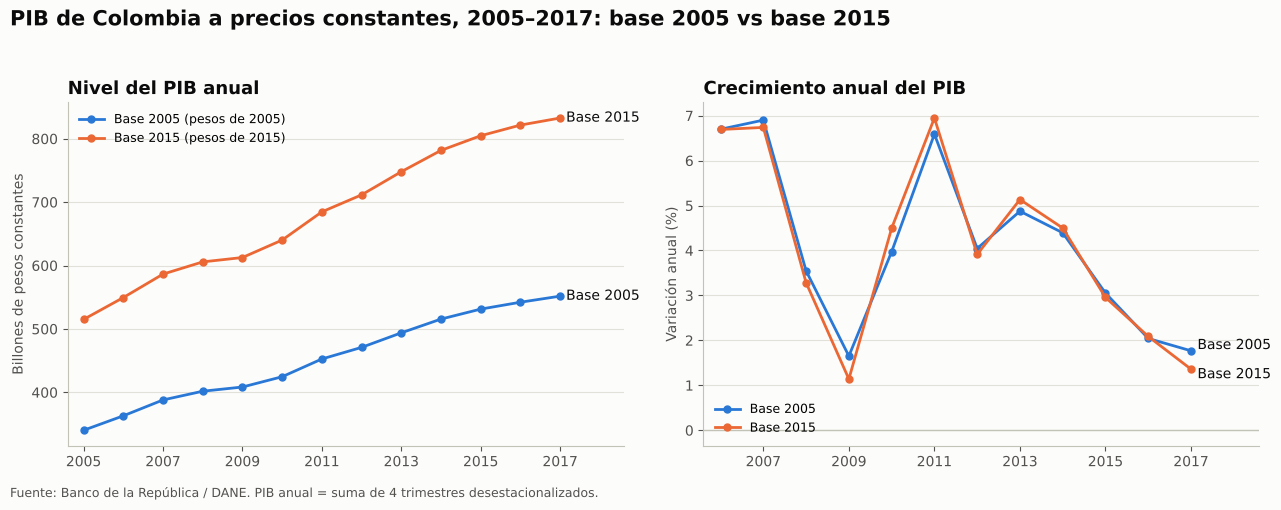

In [3]:
C05, C15 = "#2a78d6", "#eb6834"          # azul = base 2005, naranja = base 2015
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), facecolor="#fcfcfb")
for ax in (ax1, ax2):
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color=GRID, lw=0.8)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.set_xticks(range(2005, 2018, 2))

x = anual_df.index
# --- nivel
ax1.plot(x, anual_df.pib_base2005 / 1000, color=C05, lw=2, marker="o", ms=5, label="Base 2005 (pesos de 2005)")
ax1.plot(x, anual_df.pib_base2015 / 1000, color=C15, lw=2, marker="o", ms=5, label="Base 2015 (pesos de 2015)")
ax1.set_title("Nivel del PIB anual", loc="left", color=INK, fontsize=13, fontweight="bold")
ax1.set_ylabel("Billones de pesos constantes")
ax1.text(2017.15, anual_df.pib_base2005.iloc[-1] / 1000, "Base 2005", color=INK, va="center", fontsize=10)
ax1.text(2017.15, anual_df.pib_base2015.iloc[-1] / 1000, "Base 2015", color=INK, va="center", fontsize=10)
ax1.set_xlim(2004.6, 2018.6)
ax1.legend(frameon=False, loc="upper left", fontsize=9)

# --- crecimiento (2006-2017: 2005 no tiene variación en base 2015)
xg = anual_df.index[1:]
ax2.axhline(0, color="#c3c2b7", lw=1)
ax2.plot(xg, anual_df.crec_base2005[1:], color=C05, lw=2, marker="o", ms=5, label="Base 2005")
ax2.plot(xg, anual_df.crec_base2015[1:], color=C15, lw=2, marker="o", ms=5, label="Base 2015")
ax2.set_title("Crecimiento anual del PIB", loc="left", color=INK, fontsize=13, fontweight="bold")
ax2.set_ylabel("Variación anual (%)")
ax2.set_xlim(2005.6, 2018.6)
ax2.text(2017.15, anual_df.crec_base2005.iloc[-1] + 0.12, "Base 2005", color=INK, va="center", fontsize=10)
ax2.text(2017.15, anual_df.crec_base2015.iloc[-1] - 0.12, "Base 2015", color=INK, va="center", fontsize=10)
ax2.legend(frameon=False, loc="lower left", fontsize=9)

fig.suptitle("PIB de Colombia a precios constantes, 2005–2017: base 2005 vs base 2015",
             x=0.01, ha="left", color=INK, fontsize=15, fontweight="bold")
fig.text(0.01, 0.005, "Fuente: Banco de la República / DANE. PIB anual = suma de 4 trimestres desestacionalizados.",
         color=MUTED, fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
fig.savefig(FIG / "comparacion_pib_bases.png", dpi=170, facecolor=fig.get_facecolor())
plt.show()

## 3. Explicación de las diferencias

**Niveles: la base 2015 es ~51% mayor, y esa brecha es casi constante.** Ambas series son PIB a *precios constantes*, pero cada una valora la producción con los precios de un año distinto: la base 2005 en pesos de 2005 y la base 2015 en pesos de 2015. Como entre 2005 y 2015 subió el nivel general de precios, la misma producción real se expresa con una cifra mayor en pesos de 2015. La razón entre ambas series se mantiene alrededor de 1,51 todos los años (entre 1,50 y 1,52); es decir, el cambio de base **reescala** la serie, no cambia la historia que cuenta. Esta es nuestra interpretación del patrón observado.

**¿Entonces la base 2005 dice que la economía es 50% más pequeña? No.** Las dos series describen la misma economía; solo cambia la "regla" en pesos con que se mide (pesos de 2005 vs. pesos de 2015). Si un país produce 100 panes en 2005 y 120 en 2006, el crecimiento es 20% con cualquier precio; solo el nivel en pesos cambia.

**Crecimiento: casi idéntico, con diferencias pequeñas pero reales.** El crecimiento promedio 2006–2017 es 4,13% con la base 2005 y 4,10% con la base 2015, y el crecimiento acumulado anualizado 2005–2017 es 4,11% frente a 4,09%. Año a año la diferencia absoluta promedia 0,24 puntos porcentuales. Las mayores divergencias aparecen alrededor de la crisis de 2009: la base 2015 estima un crecimiento menor en 2009 (1,14% frente a 1,65%) y mayor en 2010 (4,49% frente a 3,97%), y en 2017 la base 2015 es 0,41 pp más baja (1,36% frente a 1,77%).

<p style="color:#2a78d6"><b>¿Por qué no coinciden exactamente, y por qué cambia el crecimiento promedio al cambiar la base?</b></p>

 Un cambio de año base implica más que cambiar los precios de referencia: (i) cambian los ponderadores relativos de los sectores, porque la estructura de precios y de producción de 2015 es distinta a la de 2005, y el crecimiento agregado es un promedio ponderado del crecimiento sectorial; (ii) el DANE incorpora nuevas fuentes de información y actualiza metodologías al rebasar las cuentas nacionales (ver las notas metodológicas del DANE sobre cada base); y (iii) los años de mayor cambio estructural o choque (como 2009–2010) son donde estas diferencias de ponderación y de datos pesan más.

**Conclusión.** Para analizar *cuánto crece* la economía, ambas bases cuentan prácticamente la misma historia. Para analizar *cuánto vale* el PIB, no se pueden mezclar niveles de bases distintas: hay que usar una sola serie o empalmar.

## Fuentes

- Banco de la República de Colombia, *Series estadísticas históricas de Colombia*, Producto Interno Bruto, "PIB por demanda", fila "1. PIB reportado", bases 2005 y 2015, constante desestacionalizado, trimestral (cifras DANE). Consultado el 12 de octubre de 2026. https://uba.banrep.gov.co/htmlcommons/SeriesHistoricas/producto-interno-bruto.html
- DANE, notas metodológicas de las cuentas nacionales trimestrales, bases 2005 y 2015.